In [ ]:
import os
import re
import pandas as pd

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.morphology import skeletonize, dilation, disk
from skimage.util import img_as_bool, img_as_ubyte


from scipy.stats import mannwhitneyu


from google.colab import drive

In [ ]:
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# ============================================================================
# CONFIGURAZIONE DEI PATH (GOOGLE DRIVE)
# ============================================================================
INPUT_DIR = Path("/content/drive/MyDrive/spiraliD1")
OUTPUT_DIR = Path("/content/drive/MyDrive/spirali_outputHD")
SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg"}

# Struttura DataFrame

In [ ]:

def struttura_dataset_spirali(cartella_immagini):
    """Prende una cartella contenente le immagini delle spirali e restituisce

    un DataFrame Pandas pulito e organizzato con i metadati di ogni file,
    senza scartare i file che non rispettano il formato standard.
    """
    dati_estratti = []

    # Pattern opzionale per estrarre metadati se presenti
    pattern = re.compile(r"p(\d+)t(\d+)v(\d+)", re.IGNORECASE)

    try:
        file_totali = os.listdir(cartella_immagini)
    except FileNotFoundError:
        print(f"Errore: La cartella '{cartella_immagini}' non esiste.")
        return None

    for nome_file in file_totali:
        # Salta eventuali file di sistema nascosti (es. .DS_Store su Mac)
        if nome_file.startswith("."):
            continue

        percorso_completo = os.path.join(cartella_immagini, nome_file)

        # Proviamo ad estrarre le info, ma non blocchiamo il file se non corrispondono
        match = pattern.search(nome_file)

        if match:
            id_paziente = f"P_{match.group(1)}"
            tipo_test = int(match.group(2))
            id_visita = int(match.group(3))
        else:
            id_paziente = None
            tipo_test = None
            id_visita = None

        dati_estratti.append(
            {
                "percorso_file": percorso_completo,
                "nome_file": nome_file,
                "paziente_id": id_paziente,
                "tipo_test": tipo_test,
                "visita": id_visita,
            }
        )

    df = pd.DataFrame(dati_estratti)

    # Ordiniamo ponendo in coda eventuali file privi di metadati
    if not df.empty:
        df = df.sort_values(
            by=["paziente_id", "visita", "tipo_test"], na_position="last"
        ).reset_index(drop=True)

    return df

In [ ]:
# Uso funzione
percorso_cartella = "/content/drive/MyDrive/spiraliD1"
df_progetto = struttura_dataset_spirali(percorso_cartella)

# Rimuove il limite massimo di righe da visualizzare
pd.set_option("display.max_rows", None)

#Stampa su una sola riga
pd.set_option("display.expand_frame_repr", False)

# Mostr righe del dataset
print(df_progetto)

                                    percorso_file    nome_file paziente_id tipo_test visita
0    /content/drive/MyDrive/spiraliD1/V06HE02.png  V06HE02.png        None      None   None
1    /content/drive/MyDrive/spiraliD1/V05HE02.png  V05HE02.png        None      None   None
2    /content/drive/MyDrive/spiraliD1/V07PE01.png  V07PE01.png        None      None   None
3     /content/drive/MyDrive/spiraliD1/V03HE2.png   V03HE2.png        None      None   None
4     /content/drive/MyDrive/spiraliD1/V03HE3.png   V03HE3.png        None      None   None
5    /content/drive/MyDrive/spiraliD1/V14PE03.png  V14PE03.png        None      None   None
6    /content/drive/MyDrive/spiraliD1/V15PE01.png  V15PE01.png        None      None   None
7    /content/drive/MyDrive/spiraliD1/V03PE01.png  V03PE01.png        None      None   None
8    /content/drive/MyDrive/spiraliD1/V04PE01.png  V04PE01.png        None      None   None
9    /content/drive/MyDrive/spiraliD1/V55HE15.png  V55HE15.png        None      

In [ ]:
#Salviamo nella cartella 'spirali' con il nome 'dataset_spirali.csv'
percorso_salvataggio = "/content/drive/MyDrive/dataset_spiraliHD.csv"

# 2. Salva il DataFrame in formato CSV
# Usiamo index=False per evitare che Pandas salvi anche la colonna dei numeri di riga (0, 1, 2...)
df_progetto.to_csv(percorso_salvataggio, index=False)

print(f"✅ Dataset salvato con successo in: {percorso_salvataggio}")

✅ Dataset salvato con successo in: /content/drive/MyDrive/dataset_spiraliHD.csv


# Funzioni Pre-processing

In [ ]:
import cv2
import numpy as np
from PIL import Image
from skimage.morphology import skeletonize, dilation, disk
from skimage.util import img_as_bool, img_as_ubyte

TARGET_SIZE = 224

# ============================================================================
# FUNZIONI DI PREPARAZIONE FILE
# ============================================================================

def ensure_directories():
    """Crea la cartella di output su Google Drive se non esiste"""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================================
# FUNZIONI DI PREPROCESSING IMMAGINE
# ============================================================================
def convert_to_grayscale(image):
  """Converte un'immagine a scala di grigi.
     Lavorare su un solo canale riduce a un terzo il carico computazionale e prepara l'immagine
     per le operazioni basate sull'intensità """
  return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def remove_scan_lines(gray, dark_threshold=50, coverage=0.5):
    """Rimuove le righe orizzontali artefatto da scanner tramite interpolazione.
    Meccanismo: Analizza l'immagine riga per riga. Se rileva che una riga orizzontale contiene troppi
     pixel scuri (supera il coverage del 50% della larghezza),
     la identifica come un artefatto dello scanner (es. il bordo nero del coperchio o una linea di trascinamento).
      A quel punto, sostituisce quella riga calcolando la media (interpolazione) tra i pixel della
       prima riga pulita sopra e la prima riga pulita sotto l'artefatto.

    Perché si usa: Una riga nera dello scanner verrebbe interpretata
     come parte del disegno, rovinando l'isolamento della spirale."""

    result = gray.copy()
    h, w = gray.shape

    for r in range(h):
        if np.sum(gray[r, :] < dark_threshold) > w * coverage:
            r_above, r_below = r - 1, r + 1
            while r_above >= 0 and np.sum(gray[r_above, :] < dark_threshold) > w * coverage:
                r_above -= 1
            while r_below < h and np.sum(gray[r_below, :] < dark_threshold) > w * coverage:
                r_below += 1
            if r_above >= 0 and r_below < h:
                result[r, :] = ((gray[r_above].astype(int) + gray[r_below].astype(int)) // 2).astype(np.uint8)
            elif r_above >= 0:
                result[r, :] = gray[r_above]
            else:
                result[r, :] = gray[r_below]
    return result

def whiten_background(gray, threshold=230):
    """Porta a bianco puro tutti i pixel più chiari di threshold.
    Rimuove le ombre leggere o la trama della carta."""
    result = gray.copy()
    result[result > threshold] = 255
    return result

def enhance_document(gray):
    """Migliora il contrasto localmente (CLAHE).
    Utilizza l'algoritmo CLAHE (Contrast Limited Adaptive Histogram Equalization).
    Invece di aumentare il contrasto su tutta l'immagine (che potrebbe "bruciare" alcune zone), divide l'immagine in una griglia 8x8
    e migliora il contrasto localmente in ogni quadratino.

    I pazienti con Parkinson possono applicare una pressione molto debole sulla penna in alcuni tratti. Il CLAHE fa "risaltare" i tratti deboli
    senza trasformare in rumore nero le piccole macchie della carta.
    """

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(gray)

def denoise_image(gray):
  """Fa una media pesata dei pixel vicini per sfocare
  leggermente le micro-imperfezioni (polvere, rumore del sensore)."""

  return cv2.GaussianBlur(gray, (3, 3), 0)

def close_gaps(binary):
    """Chiusura morfologica: ricollega tratti spezzati.
    Meccanismo: Utilizza un'operazione morfologica chiamata Closing (Chiusura).
    Consiste in una Dilatazione (ingrossa il tratto) seguita immediatamente da
    un'Erosione (lo restringe della stessa quantità).

Perché si usa: Se il paziente ha sollevato impercettibilmente la penna o se lo scanner ha "perso" un pixel del tratto, si creano dei micro-buchi nella spirale. La chiusura fonde i pixel vicini, "tappando" queste micro-interruzioni e
 garantendo che la spirale sia un'unica linea continua."""
    inverted = cv2.bitwise_not(binary)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    closed = cv2.morphologyEx(inverted, cv2.MORPH_CLOSE, kernel)
    return cv2.bitwise_not(closed)

def keep_main_spiral(binary):
    """Mantiene solo la componente connessa più grande (la spirale).
    Raggruppa tutti i pixel neri che si toccano tra loro in "isole" (blobs).
     Poi calcola l'area di ogni isola, individua quella più grande (che sarà matematicamente la spirale)
     e cancella (colora di bianco) tutte le altre."""
    inv = cv2.bitwise_not(binary)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(inv, connectivity=8)
    if num_labels <= 1:
        return binary
    areas = stats[1:, cv2.CC_STAT_AREA]
    largest_label = np.argmax(areas) + 1

    mask = (labels == largest_label).astype(np.uint8) * 255
    result = np.full_like(binary, 255)
    result[mask > 0] = 0
    return result

def binarize_image(gray):
    """Binarizzazione adattiva locale.
    Invece di decidere un livello di grigio fisso per separare l'inchiostro
     dalla carta, calcola la soglia ideale per ogni singolo pixel guardando
     il vicinato"""
    return cv2.adaptiveThreshold(
        gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, blockSize=51, C=10
    )


def smooth_stroke_skeleton(binary, radius=3):
    """Scheletrizza e ridilata a spessore uniforme, prevenendo gli speroni (spurs)."""
    # Invertiamo l'immagine (il tratto deve essere bianco su sfondo nero)
    inv = cv2.bitwise_not(binary)

    # 1. LISCIATURA DEI CONTORNI
    # Un leggero blur gaussiano fonde le seghettature del bordo
    blurred = cv2.GaussianBlur(inv, (5, 5), 0)
    # Re-binarizziamo l'immagine sfocata per ottenere bordi netti ma lisci
    _, smoothed = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)

    # 2. APERTURA MORFOLOGICA
    # Rimuove eventuali micro-sporgenze appuntite sopravvissute al blur
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    smoothed = cv2.morphologyEx(smoothed, cv2.MORPH_OPEN, kernel)

    # 3. SCHELETRIZZAZIONE
    # Ora che i bordi sono perfettamente lisci, non si genereranno falsi rami
    skel = skeletonize(img_as_bool(smoothed))

    # 4. DILATAZIONE
    # Riportiamo il tratto allo spessore uniforme desiderato
    dilated = dilation(skel, disk(radius))

    return img_as_ubyte(~dilated)

# ============================================================================
# ANALISI GEOMETRICA E COORDINATE
# ============================================================================
def find_spiral_center(binary_image):
    """Trova il centro biologico della spirale (endpoint interno o cerchio minimo)."""
    inv = cv2.bitwise_not(binary_image)
    skel = skeletonize(img_as_bool(inv)).astype(np.uint8)

    kernel = np.ones((3, 3), np.uint8)
    neighbor_count = cv2.filter2D(skel.astype(np.float32), -1, kernel.astype(np.float32))
    endpoints_mask = (skel == 1) & (neighbor_count == 2)
    endpoint_coords = np.column_stack(np.where(endpoints_mask))

    moments = cv2.moments(inv)
    if moments["m00"] == 0:
        return None
    bary_x = moments["m10"] / moments["m00"]
    bary_y = moments["m01"] / moments["m00"]

    if len(endpoint_coords) == 0:
        return (int(bary_x), int(bary_y))

    dists = np.sqrt((endpoint_coords[:, 1] - bary_x) ** 2 + (endpoint_coords[:, 0] - bary_y) ** 2)
    nearest = np.argmin(dists)
    cy, cx = endpoint_coords[nearest]
    candidate = (int(cx), int(cy))

    skel_coords = np.column_stack(np.where(skel == 1))
    dists_all = np.sqrt((skel_coords[:, 1] - bary_x) ** 2 + (skel_coords[:, 0] - bary_y) ** 2)
    max_radius = dists_all.max()

    for fraction in [0.20, 0.25, 0.30, 0.40]:
        inner_mask = dists_all <= max_radius * fraction
        inner_coords = skel_coords[inner_mask]
        if len(inner_coords) >= 10:
            break

    if len(inner_coords) < 10:
        return candidate

    pts = inner_coords[:, ::-1].astype(np.float32)
    x, y = pts[:, 0], pts[:, 1]

    A = np.column_stack([x, y, np.ones_like(x)])
    b = -(x**2 + y**2)

    # Il codice estrae direttamente l'array di 3 elementi (D, E, F)
    result = np.linalg.lstsq(A, b, rcond=None)[0]
    D, E, F = result
    circle_cx = -D / 2
    circle_cy = -E / 2
    circle_r = np.sqrt(circle_cx**2 + circle_cy**2 - F)

    dist_to_circle_center = np.sqrt((candidate[0] - circle_cx) ** 2 + (candidate[1] - circle_cy) ** 2)

    if dist_to_circle_center <= circle_r * 1.5:
        return candidate
    else:
        dist_ep = np.sqrt((endpoint_coords[:, 1] - circle_cx) ** 2 + (endpoint_coords[:, 0] - circle_cy) ** 2)
        nearest_corrected = np.argmin(dist_ep)
        cy2, cx2 = endpoint_coords[nearest_corrected]
        return (int(cx2), int(cy2))

def detect_rotation_angle(binary_image):
    """ Individua tutti i pixel appartenenti alla spirale e calcola il "Minimum Bounding Rect" (cv2.minAreaRect),
        ovvero il rettangolo più piccolo in assoluto capace di contenere il disegno, che spesso risulta inclinato.
    """

    inverted = cv2.bitwise_not(binary_image)
    coords = np.column_stack(np.where(inverted > 0))
    if len(coords) < 50:
        return 0.0
    rect = cv2.minAreaRect(coords)
    angle = rect[-1]
    if angle < -45:
        angle = 90 + angle
    return float(-angle)


def normalize_spiral_size(binary_image, target_size=TARGET_SIZE):
    """ Prende le coordinate del "centro biologico" scoperte da find_spiral_center e
        applica una traslazione matematica all'intera
        immagine per far coincidere quel punto esatto con
        il centro geometrico dell'inquadratura. """

    h, w = binary_image.shape
    scale = min(
        target_size / w,
        target_size / h
    )
    new_w = int(w * scale)
    new_h = int(h * scale)
    resized = cv2.resize(
        binary_image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )
    canvas = np.full(
        (target_size, target_size),
        255,
        dtype=np.uint8
    )
    x = (target_size - new_w) // 2
    y = (target_size - new_h) // 2
    canvas[y:y + new_h, x:x + new_w] = resized
    return canvas

def rotate_image(image, angle):
    (h, w) = image.shape[:2]
    center = (w // 2, h // 2)
    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
    cos, sin = abs(matrix[0, 0]), abs(matrix[0, 1])
    new_w = int((h * sin) + (w * cos))
    new_h = int((h * cos) + (w * sin))
    matrix[0, 2] += (new_w / 2) - center[0]
    matrix[1, 2] += (new_h / 2) - center[1]
    return cv2.warpAffine(
        image, matrix, (new_w, new_h),
        flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=255
    )

def crop_document(binary_image):
    inverted = cv2.bitwise_not(binary_image)
    coords = cv2.findNonZero(inverted)
    if coords is None:
        return binary_image
    x, y, w, h = cv2.boundingRect(coords)
    padding = 10
    x1 = max(0, x - padding)
    y1 = max(0, y - padding)
    x2 = min(binary_image.shape[1], x + w + padding)
    y2 = min(binary_image.shape[0], y + h + padding)
    return binary_image[y1:y2, x1:x2]





def center_spiral(binary_image, center):
    h, w = binary_image.shape
    cx, cy = center
    tx = w // 2 - cx
    ty = h // 2 - cy
    M = np.float32(
        [[1, 0, tx],
        [0, 1, ty]]
    )
    shifted = cv2.warpAffine(
        binary_image,
        M,
        (w, h),
        borderValue=255
    )
    return shifted

def save_with_pillow(image, output_path):
    Image.fromarray(image).save(output_path)

# ============================================================================
# PIPELINE DI ELABORAZIONE PRINCIPALE
# ============================================================================
def process_image(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Impossibile leggere: {image_path}")

    original_size = (image.shape[1], image.shape[0])

    # Preprocessing
    gray = convert_to_grayscale(image)
    gray = remove_scan_lines(gray)
    gray = whiten_background(gray, threshold=230)
    enhanced = enhance_document(gray)
    denoised = denoise_image(enhanced)
    binary = binarize_image(denoised)

    # Morfologia e pulizia
    binary = close_gaps(binary)
    binary = keep_main_spiral(binary)
    binary = smooth_stroke_skeleton(binary)

    # Rilevamento centro (Immagine di Debug)
    center = find_spiral_center(binary)
    debug = cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR)
    if center is not None:
        cv2.circle(debug, center, radius=10, color=(0, 0, 255), thickness=-1)

    # Orientamento e Ritaglio finale
    angle = detect_rotation_angle(binary)
    rotated = rotate_image(binary, angle)
    cropped = crop_document(rotated)
    final_size = (cropped.shape[1], cropped.shape[0])

    #save_with_pillow(cropped, OUTPUT_DIR / image_path.name)
    save_with_pillow(debug, OUTPUT_DIR / f"debug_{image_path.name}")

    return angle, original_size, final_size



def pulisci_cartella_da_vecchi_file(cartella):
    print(f"🔍 Controllo la cartella: {cartella}")

    # Controlla se la cartella esiste
    if not cartella.exists():
        print("La cartella specificata non esiste!")
        return

    file_eliminati = 0
    file_mantenuti = 0

    # Scansiona tutti gli elementi nella cartella
    for file_path in cartella.iterdir():
        # Controlliamo che sia un file e NON inizi con "debug_"
        if file_path.is_file():
            if not file_path.name.startswith("debug_"):
                file_path.unlink()  # Comando che elimina fisicamente il file
                print(f"🗑️ Eliminato: {file_path.name}")
                file_eliminati += 1
            else:
                file_mantenuti += 1

    print("-" * 50)
    print("✅ Pulizia completata!")
    print(f"File di debug mantenuti: {file_mantenuti}")

# Pre-processing spirali

In [ ]:
# 1. Caricamento del dataset da Google Drive
df_progetto = pd.read_csv("/content/drive/MyDrive/dataset_spiraliHD.csv")

# 2. FILTRO CORRETTO: Usa la colonna tipo_test per isolare i file con "t4" (31 righe totali)
df_t4 =df_progetto  #df_progetto[df_progetto["tipo_test"] == 4]

print(f"Righe totali nel dataset originale: {len(df_progetto)}")

print("-" * 80)

# Viene ripristinata l'esecuzione diretta senza blocco sulla cartella di output
ensure_directories()
report_elaborazione = []

# Controllo di sicurezza sull'esistenza della cartella di input delle immagini
if not df_t4.empty:
    cartella_input = Path(df_t4.iloc[0]["percorso_file"]).parent
    if not cartella_input.exists():
        print(
            f"ERRORE CRITICO: La cartella di input '{cartella_input}' non esiste su Drive."
        )
        raise FileNotFoundError(f"Cartella non trovata: {cartella_input}")
else:
    print("⚠️ Nessun dato relativo a tipo_test == 4 trovato nel CSV.")
    cartella_input = None

if cartella_input and cartella_input.exists():
    print("🚀 Avvio del preprocessing automatico sulle immagini...\n")

    # Ciclo diretto sulle righe del DataFrame filtrato
    for index, riga in df_t4.iterrows():
        image_path = Path(riga["percorso_file"])

        # Controllo esistenza del singolo file di input per evitare crash
        if not image_path.exists():
            print(f"⚠️ File mancante sul disco: {image_path.name} -> Saltato.")
            continue

        try:
            # Eseguiamo la pipeline di pulizia sull'immagine
            angle, original_size, final_size = process_image(image_path)

            # Stampa del progresso riga per riga
            print(
                f"✅ Elaborato: {image_path.name:<30} | Rotazione: {angle:>6.2f}° | Risoluzione Finale: {final_size}"
            )

            # Salviamo i dati nel report
            report_elaborazione.append(
                {
                    "paziente_id": riga["paziente_id"],
                    "tipo_test": riga["tipo_test"],
                    "visita": riga["visita"],
                    "nome_file": image_path.name,
                    "percorso_file": str(OUTPUT_DIR / image_path.name),
                    "angolo_rotazione": angle,
                }
            )

        except Exception as exc:
            print(f"❌ Errore imprevisto su {image_path.name}: {exc}")

    print("-" * 80)

    # Creazione del DataFrame finale accessibile nel notebook
    df_t4_pronto = pd.DataFrame(report_elaborazione)
    print(f"\n Fine elaborazione! Le immagini pulite sono in: {OUTPUT_DIR}")
    print(
        f" Le immagini sono pronte all'uso con {len(df_t4_pronto)} righe."
    )



Righe totali nel dataset originale: 102
--------------------------------------------------------------------------------
🚀 Avvio del preprocessing automatico sulle immagini...

✅ Elaborato: V06HE02.png                    | Rotazione: -44.32° | Risoluzione Finale: (267, 266)
✅ Elaborato: V05HE02.png                    | Rotazione: -25.23° | Risoluzione Finale: (267, 269)
✅ Elaborato: V07PE01.png                    | Rotazione:  25.35° | Risoluzione Finale: (297, 251)
✅ Elaborato: V03HE2.png                     | Rotazione: -40.71° | Risoluzione Finale: (255, 275)
✅ Elaborato: V03HE3.png                     | Rotazione:  41.86° | Risoluzione Finale: (266, 263)
✅ Elaborato: V14PE03.png                    | Rotazione:  -0.00° | Risoluzione Finale: (256, 256)
✅ Elaborato: V15PE01.png                    | Rotazione:  13.24° | Risoluzione Finale: (278, 276)
✅ Elaborato: V03PE01.png                    | Rotazione: -16.48° | Risoluzione Finale: (254, 282)
✅ Elaborato: V04PE01.png               

In [ ]:
# Esegui la funzione passando la tua cartella di output
pulisci_cartella_da_vecchi_file(OUTPUT_DIR)

🔍 Controllo la cartella: /content/drive/MyDrive/spirali_outputHD
--------------------------------------------------
✅ Pulizia completata!
File di debug mantenuti: 102


# ESTRAZIONE FEATURES

🚀 Avvio estrazione di TUTTE le feature geometriche e spettrali...

🖼️ Trovate 102 immagini valide. Avvio elaborazione...



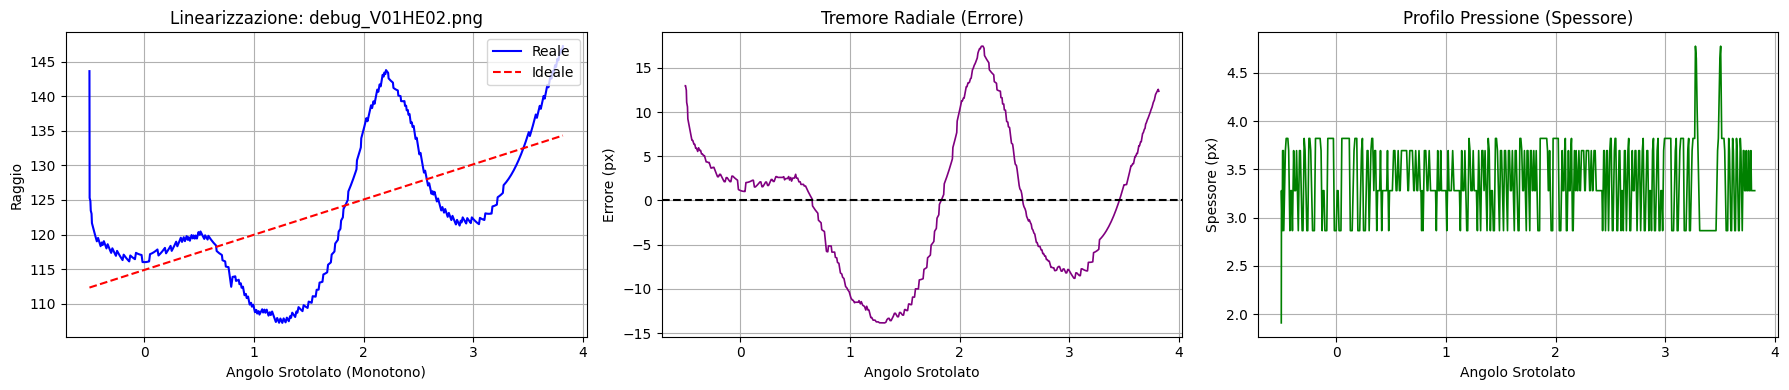

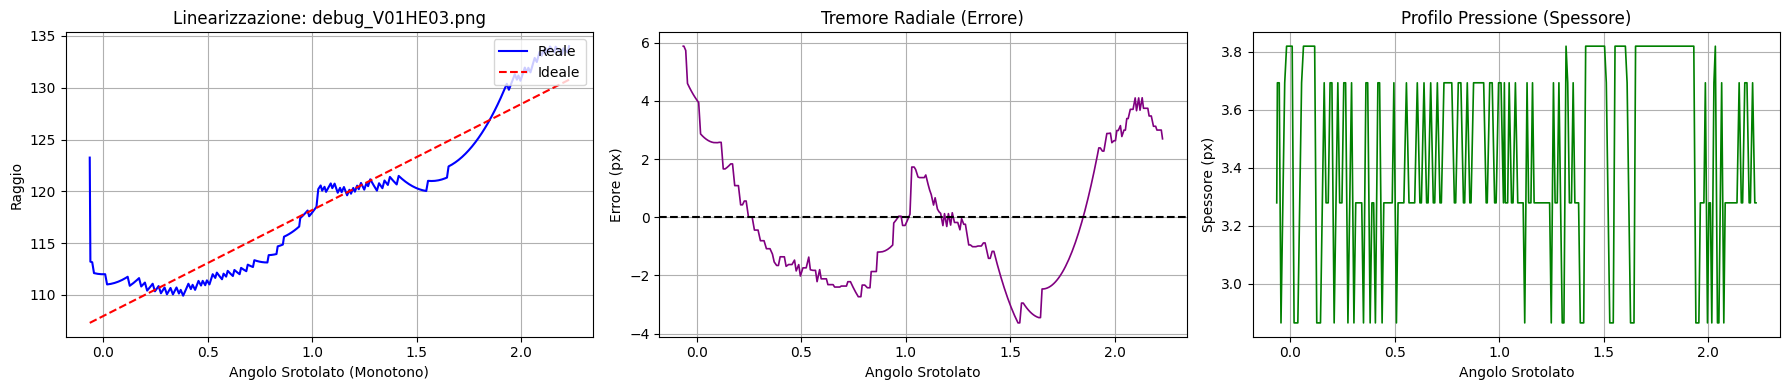

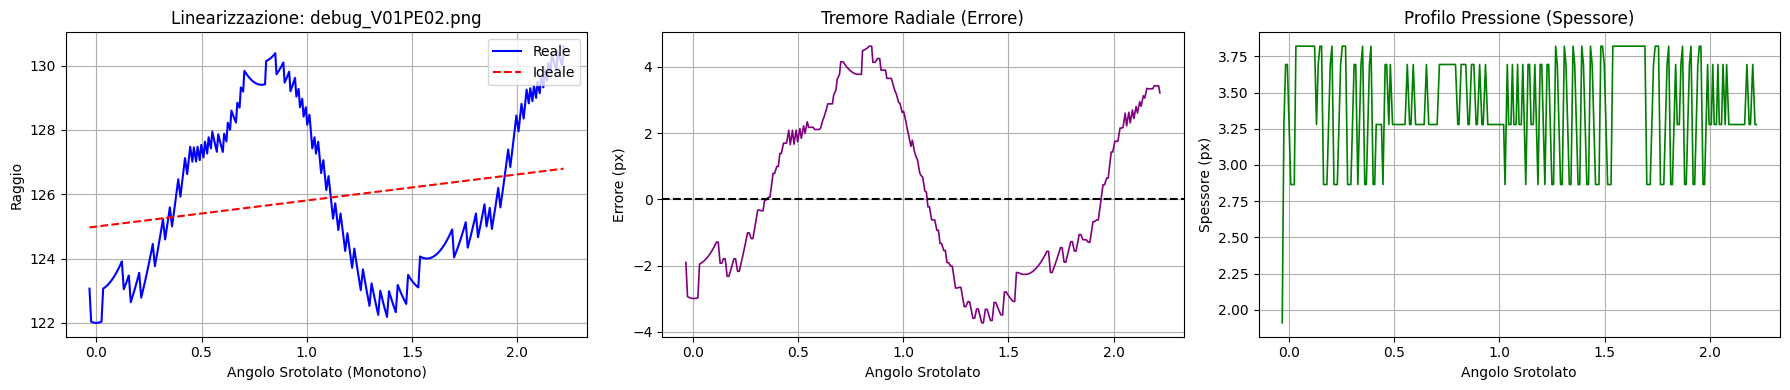

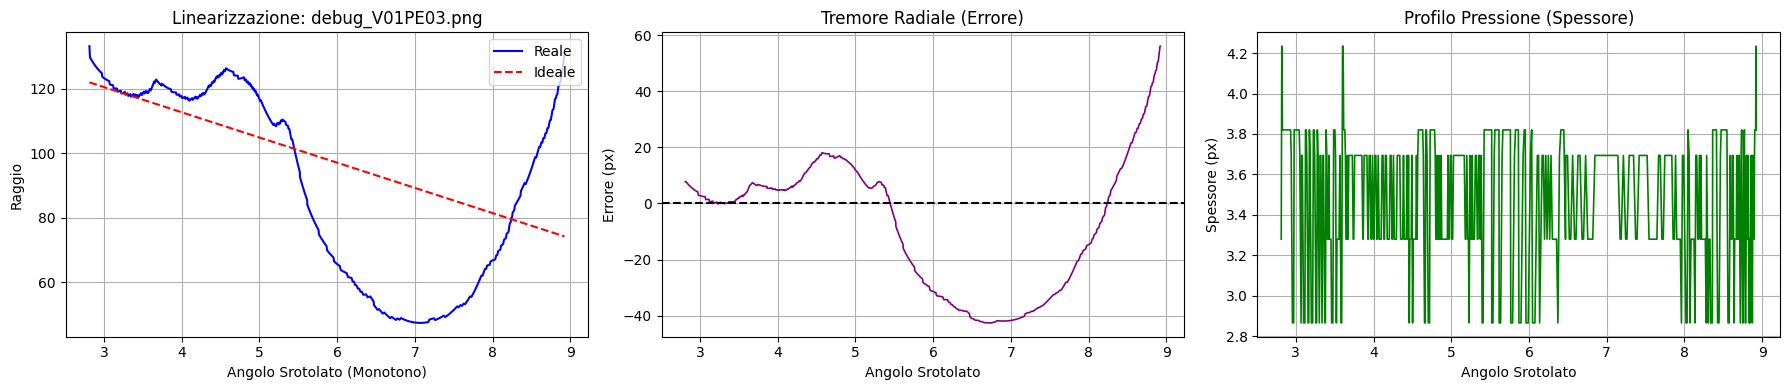

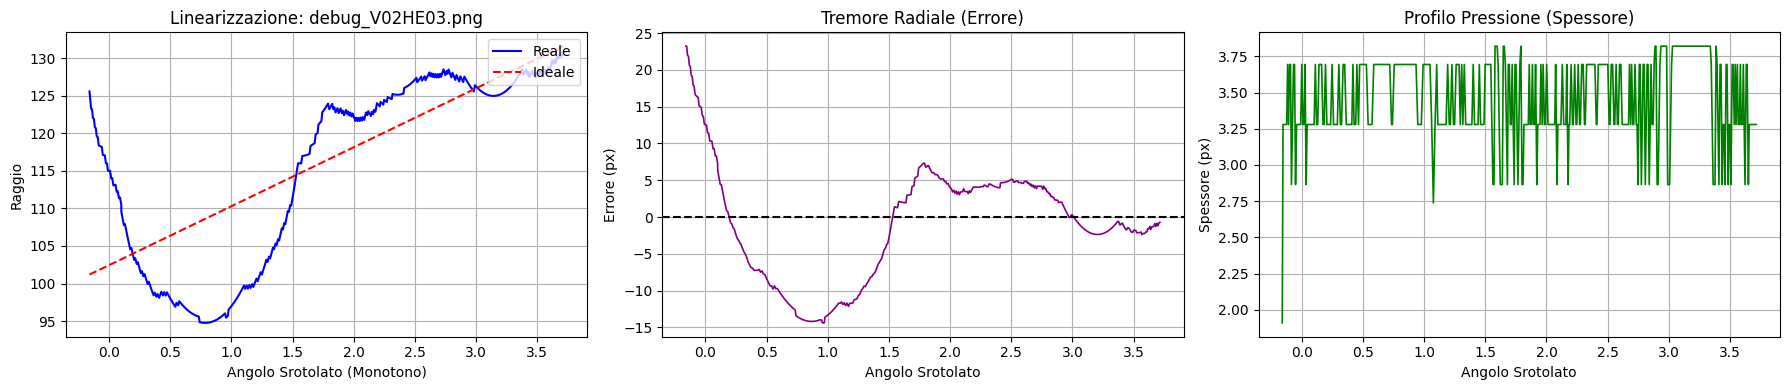

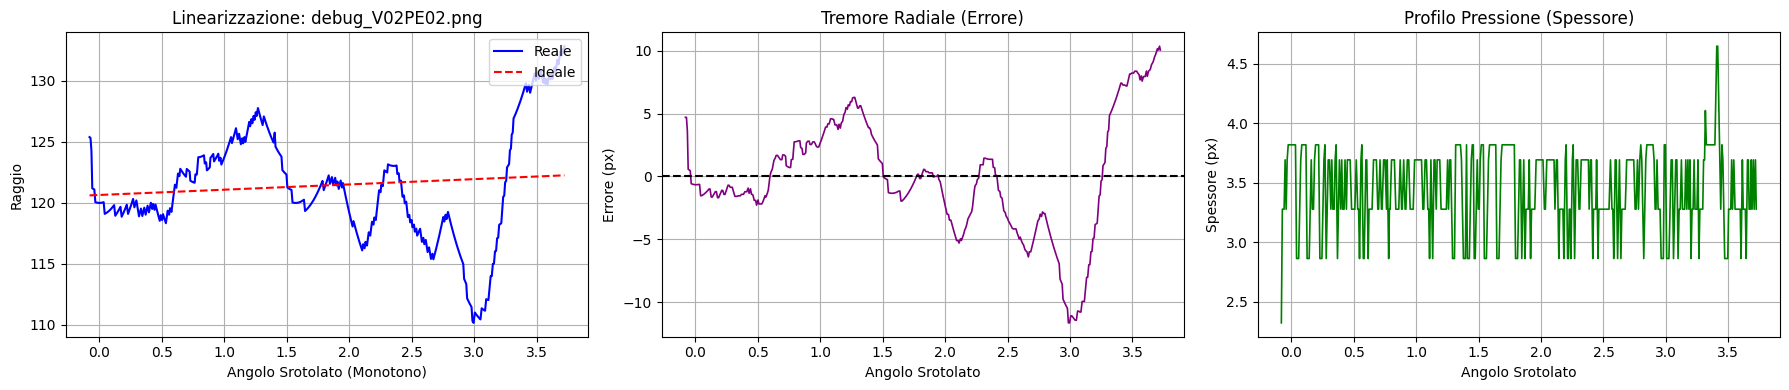

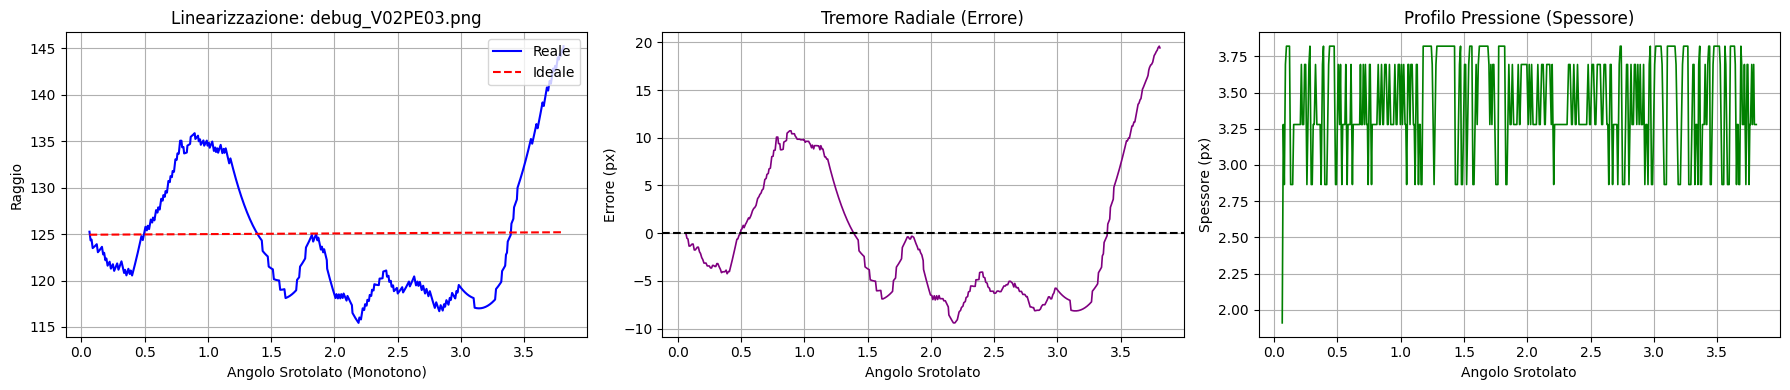

/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 43, using nperseg = 43
  freqs, psd = welch(error_signal, fs=1.0)


✅ Feature salvate: debug_V03PE03.png
✅ Feature salvate: debug_V03PE06.png
✅ Feature salvate: debug_V03PE08.png
✅ Feature salvate: debug_V04PE03.png
✅ Feature salvate: debug_V05HE02.png
✅ Feature salvate: debug_V05HE03.png


/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 226, using nperseg = 226
  freqs, psd = welch(error_signal, fs=1.0)
/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 36, using nperseg = 36
  freqs, psd = welch(error_signal, fs=1.0)
/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 200, using nperseg = 200
  freqs, psd = welch(error_signal, fs=1.0)


✅ Feature salvate: debug_V06HE01.png
✅ Feature salvate: debug_V06PE01.png
✅ Feature salvate: debug_V06PE02.png


/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 61, using nperseg = 61
  freqs, psd = welch(error_signal, fs=1.0)
/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 30, using nperseg = 30
  freqs, psd = welch(error_signal, fs=1.0)


...

✅ Feature salvate: debug_V13PE02.png
✅ Feature salvate: debug_V13PE03.png
✅ Feature salvate: debug_V14PE01.png
✅ Feature salvate: debug_V14PE02.png
✅ Feature salvate: debug_V14PE03.png


/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 217, using nperseg = 217
  freqs, psd = welch(error_signal, fs=1.0)
/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 212, using nperseg = 212
  freqs, psd = welch(error_signal, fs=1.0)
/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 51, using nperseg = 51
  freqs, psd = welch(error_signal, fs=1.0)


✅ Feature salvate: debug_V55HE02.png
✅ Feature salvate: debug_V55HE03.png
✅ Feature salvate: debug_V55HE05.png


/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 241, using nperseg = 241
  freqs, psd = welch(error_signal, fs=1.0)
/tmp/ipykernel_1398/2365095490.py:182: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 183, using nperseg = 183
  freqs, psd = welch(error_signal, fs=1.0)


✅ Feature salvate: debug_V55HE11.png
✅ Feature salvate: debug_V55HE13.png
--------------------------------------------------------------------------------

🎉 Fusione completata! Dataset salvato in: /content/drive/MyDrive/dataset_spirali_features_complete.csv

Ecco un'anteprima delle colonne salvate:
['nome_file', 'error_distance_mean', 'tremore_rms', 'tremore_std', 'frequenza_dominante_rad', 'mean_frequency_mnf_rad', 'psd_tremor_band_energy_rad', 'kurtosis', 'skewness', 'mean_absolute_value_mav', 'fractal_dimension_katz', 'approximate_entropy', 'lunghezza_spirale_reale', 'dct_mnf', 'dct_wamp', 'dct_fractal_dimension', 'pressione_media_px', 'pressione_std_px', 'pressione_cv', 'pressione_range_px', 'pressione_fractal_dimension_katz', 'pressione_num_variazioni_significative']


In [ ]:
%matplotlib inline

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re
from scipy.signal import welch, medfilt
from scipy.stats import kurtosis, skew
from scipy.fftpack import dct
from skimage.morphology import skeletonize
from skimage.util import img_as_bool

# ============================================================================
# 1. FUNZIONI MATEMATICHE PER LE FEATURE
# ============================================================================

def katz_fd(signal):
    """Dimensione Frattale di Katz ottimizzata e protetta numericamente."""
    signal = np.array(signal)
    n = len(signal) - 1
    if n < 2: return 1.0

    L = np.sum(np.abs(np.diff(signal)))
    d = np.max(np.abs(signal - signal[0]))

    if d == 0 or L == 0 or L <= d:
        return 1.0

    ratio = d / L
    log_n = np.log10(n)
    denom = log_n + np.log10(ratio)

    if denom == 0: return 1.0

    fd = log_n / denom
    # Vincoliamo il risultato nei limiti teorici validi [1.0, 2.0]
    return float(np.clip(fd, 1.0, 2.0))

def robust_bowley_skewness(signal):
    """
    Skewness robusta basata sui quartili (Bowley / Quartile Skewness).
    Molto più stabile della skewness classica contro i rumori di tratto a mano libera.
    """
    signal = np.array(signal)
    if len(signal) < 4: return 0.0

    q25, q50, q75 = np.percentile(signal, [25, 50, 75])
    iqr = q75 - q25

    if iqr == 0: return 0.0

    # Formula di Bowley: (Q3 + Q1 - 2*Mediana) / IQR
    skew_val = (q75 + q25 - (2 * q50)) / iqr
    return float(np.clip(skew_val, -1.0, 1.0))

def approximate_entropy(U, m=2, r=None):
    U = np.array(U)
    if r is None:
        r = 0.2 * np.std(U)
    if len(U) <= m + 1 or r == 0:
        return 0.0
    def _phi(m):
        N = len(U)
        x = np.array([U[i:i+m] for i in range(N - m + 1)])
        C = np.sum(np.max(np.abs(x[:, None, :] - x[None, :, :]), axis=-1) <= r, axis=0) / (N - m + 1)
        return np.sum(np.log(C)) / (N - m + 1)
    return np.abs(_phi(m) - _phi(m + 1))

def willison_amplitude(signal, threshold=None):
    if threshold is None:
        threshold = 0.1 * np.std(signal)
    diffs = np.abs(np.diff(signal))
    return np.sum(diffs > threshold)

# ============================================================================
# 2. MOTORE DI TRACCIAMENTO SPIRALE
# ============================================================================

def traccia_spirale_esterno_interno(skel, cx, cy):
    y_coords, x_coords = np.where(skel > 0)
    if len(x_coords) == 0: return np.array([])

    dists = (x_coords - cx)**2 + (y_coords - cy)**2
    start_idx = np.argmax(dists)
    start_pt = (x_coords[start_idx], y_coords[start_idx])

    visited = set([start_pt])
    path = [start_pt]
    curr = start_pt

    while True:
        possible_nexts = []
        for dx in [-1, 0, 1]:
            for dy in [-1, 0, 1]:
                if dx == 0 and dy == 0: continue
                nx, ny = curr[0] + dx, curr[1] + dy
                if (nx, ny) not in visited and 0 <= ny < skel.shape[0] and 0 <= nx < skel.shape[1]:
                    if skel[ny, nx] > 0: possible_nexts.append((nx, ny))

        if not possible_nexts:
            for dx in [-2, -1, 0, 1, 2]:
                for dy in [-2, -1, 0, 1, 2]:
                    nx, ny = curr[0] + dx, curr[1] + dy
                    if (nx, ny) not in visited and 0 <= ny < skel.shape[0] and 0 <= nx < skel.shape[1]:
                        if skel[ny, nx] > 0: possible_nexts.append((nx, ny))

        if not possible_nexts: break

        best_next = min(possible_nexts, key=lambda p: (p[0]-curr[0])**2 + (p[1]-curr[1])**2)
        visited.add(best_next)
        path.append(best_next)
        curr = best_next

    return np.array(path)

# ============================================================================
# 3. PIPELINE DI ESTRAZIONE
# ============================================================================

def process_and_extract_features(image_path, plot_graphs=True):
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if image is None: return None

    _, binary = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)
    skel = skeletonize(img_as_bool(binary)).astype(np.uint8)
    dist_transform = cv2.distanceTransform(binary, cv2.DIST_L2, 3)

    h, w = image.shape
    cx, cy = w // 2, h // 2

    ordered_pts = traccia_spirale_esterno_interno(skel, cx, cy)
    if len(ordered_pts) < 50: return None

    ordered_pts = ordered_pts[::-1]
    x_final = ordered_pts[:, 0]
    y_final = ordered_pts[:, 1]

    dx = x_final - cx
    dy = y_final - cy
    r_final = np.sqrt(dx**2 + dy**2)
    theta_raw = np.arctan2(dy, dx)

    theta_unwrapped = np.unwrap(theta_raw)

    # --- FILTRO DI MONOTONICITÀ (Rimuove i ripiegamenti e i cappi) ---
    valid_idx = np.ones(len(theta_unwrapped), dtype=bool)
    max_theta = -np.inf
    for i in range(len(theta_unwrapped)):
        if theta_unwrapped[i] >= max_theta:
            max_theta = theta_unwrapped[i]
        else:
            valid_idx[i] = False # Scarta i punti in cui il tratto torna indietro

    theta_clean = theta_unwrapped[valid_idx]
    r_clean = r_final[valid_idx]
    x_clean = x_final[valid_idx]
    y_clean = y_final[valid_idx]

    if len(theta_clean) < 30: return None

    # Modello Spirale Ideale (Fit Lineare sui dati puliti)
    A = np.vstack([theta_clean, np.ones(len(theta_clean))]).T
    m, c = np.linalg.lstsq(A, r_clean, rcond=None)[0]
    ideal_radius = m * theta_clean + c

    error_signal = r_clean - ideal_radius
    error_signal = medfilt(error_signal, kernel_size=3)

    pressure_signal = dist_transform[y_clean, x_clean]

    freqs, psd = welch(error_signal, fs=1.0)
    dct_signal = dct(error_signal, type=2, norm='ortho')

    lunghezza_spirale_reale = np.sum(np.sqrt(np.diff(x_clean)**2 + np.diff(y_clean)**2))

    features = {
        # --- Metriche di Errore e Tremore Radiale ---
        "error_distance_mean": float(np.mean(np.abs(error_signal))) if len(error_signal) > 0 else 0.0,
        "tremore_rms": float(np.sqrt(np.mean(error_signal**2))) if len(error_signal) > 0 else 0.0,
        "tremore_std": float(np.std(error_signal)) if len(error_signal) > 0 else 0.0,

        # --- Analisi Spettrale (Metodo di Welch) ---
        "frequenza_dominante_rad": float(freqs[np.argmax(psd)]) if len(psd) > 0 and np.max(psd) > 0 else 0.0,
        "mean_frequency_mnf_rad": float(np.sum(freqs * psd) / np.sum(psd)) if len(psd) > 0 and np.sum(psd) > 0 else 0.0,
        "psd_tremor_band_energy_rad": float(np.sum(psd)) if len(psd) > 0 else 0.0,

        # --- Statistiche Avanzate e Complessità (Migliorate) ---
        "kurtosis": float(kurtosis(error_signal)) if len(error_signal) > 3 else 0.0,
        "skewness": robust_bowley_skewness(error_signal), # Usiamo la skewness robusta
        "mean_absolute_value_mav": float(np.mean(np.abs(error_signal))) if len(error_signal) > 0 else 0.0,
        "fractal_dimension_katz": katz_fd(error_signal), # Katz FD stabilizzato
        "approximate_entropy": approximate_entropy(error_signal) if len(error_signal) > 2 else 0.0,
        "lunghezza_spirale_reale": float(lunghezza_spirale_reale),

        # --- Trasformata Discreta dei Coseni (DCT) ---
        "dct_mnf": float(np.sum(np.abs(dct_signal) * np.arange(len(dct_signal))) / np.sum(np.abs(dct_signal))) if len(dct_signal) > 0 and np.sum(np.abs(dct_signal)) > 0 else 0.0,
        "dct_wamp": int(willison_amplitude(dct_signal)),
        "dct_fractal_dimension": katz_fd(dct_signal),

        # --- Profilo di Pressione e Spessore del Tratto ---
        "pressione_media_px": float(np.mean(pressure_signal)) if len(pressure_signal) > 0 else 0.0,
        "pressione_std_px": float(np.std(pressure_signal)) if len(pressure_signal) > 0 else 0.0,
        "pressione_cv": float(np.std(pressure_signal) / np.mean(pressure_signal)) if len(pressure_signal) > 0 and np.mean(pressure_signal) > 0 else 0.0,
        "pressione_range_px": float(np.ptp(pressure_signal)) if len(pressure_signal) > 0 else 0.0,
        "pressione_fractal_dimension_katz": katz_fd(pressure_signal),
        "pressione_num_variazioni_significative": int(willison_amplitude(
            pressure_signal,
            threshold=0.2 * np.std(pressure_signal) if len(pressure_signal) > 0 else 0.5
        ))
    }

    # --- STAMPA DEL GRAFICO PULITO ---
    if plot_graphs:
        fig, axs = plt.subplots(1, 3, figsize=(18, 4))

        axs[0].plot(theta_clean, r_clean, label="Reale", color="blue", linewidth=1.5)
        axs[0].plot(theta_clean, ideal_radius, label="Ideale", color="red", linestyle="--")
        axs[0].set_title(f"Linearizzazione: {image_path.name}")
        axs[0].set_xlabel("Angolo Srotolato (Monotono)")
        axs[0].set_ylabel("Raggio")
        axs[0].legend(loc="upper right")
        axs[0].grid(True)

        axs[1].plot(theta_clean, error_signal, color="purple", linewidth=1.2)
        axs[1].axhline(0, color='black', linestyle='--')
        axs[1].set_title("Tremore Radiale (Errore)")
        axs[1].set_xlabel("Angolo Srotolato")
        axs[1].set_ylabel("Errore (px)")
        axs[1].grid(True)

        axs[2].plot(theta_clean, pressure_signal, color="green", linewidth=1.2)
        axs[2].set_title("Profilo Pressione (Spessore)")
        axs[2].set_xlabel("Angolo Srotolato")
        axs[2].set_ylabel("Spessore (px)")
        axs[2].grid(True)

        plt.tight_layout()
        plt.show()

    return features

# ============================================================================
# 4. ESECUZIONE
# ============================================================================

print("🚀 Avvio estrazione di TUTTE le feature geometriche e spettrali...\n")

DIR_SORGENTE = Path("/content/drive/MyDrive/spirali_outputHD")
SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg"}
risultati_finali = []

file_immagini_non_ordinati = [f for f in DIR_SORGENTE.glob("*") if f.suffix.lower() in SUPPORTED_EXTENSIONS]

def chiave_ordinamento(filepath):
    nome = filepath.stem.replace("debug_", "")
    match = re.search(r"V(\d+)(HE|PE)(\d+)", nome, re.IGNORECASE)
    if match: return (int(match.group(1)), match.group(2).upper(), int(match.group(3)))
    return (9999, nome, 0)

file_immagini = sorted(file_immagini_non_ordinati, key=chiave_ordinamento)
print(f"🖼️ Trovate {len(file_immagini)} immagini valide. Avvio elaborazione...\n")

# Mostra i grafici solo per le prime n
NUMERO_MASSIMO_GRAFICI = 15

for idx, filepath in enumerate(file_immagini):
    mostra_grafici = (idx < NUMERO_MASSIMO_GRAFICI)

    try:
        features_estratte = process_and_extract_features(filepath, plot_graphs=mostra_grafici)

        if features_estratte is not None:
            record = {"nome_file": filepath.name}
            record.update(features_estratte)
            risultati_finali.append(record)
            if not mostra_grafici:
                print(f"✅ Feature salvate: {filepath.name}")
        # else:
        #     print(f"⚠️ Immagine scartata (non leggibile): {filepath.name}")

    except Exception as e:
        # Se c'è un errore, lo stamperà chiaramente a schermo
        print(f"❌ ERRORE SU {filepath.name}: {str(e)}")

print("-" * 80)

if len(risultati_finali) > 0:
    df_features = pd.DataFrame(risultati_finali)

    try:
        df_dataset_completo = pd.merge(df_t4_pronto, df_features, on="nome_file", how="inner")
        percorso_csv = "/content/drive/MyDrive/dataset_spirali_features_complete.csv"
        df_dataset_completo.to_csv(percorso_csv, index=False)
        print(f"\n🎉 Fusione completata! Dataset salvato in: {percorso_csv}")
    except NameError:
        percorso_csv = "/content/drive/MyDrive/solo_features_spirali_complete.csv"
        df_features.to_csv(percorso_csv, index=False)
        print(f"\n🎉 Estrazione completata! Dataset salvato in: {percorso_csv}")

    print("\nEcco un'anteprima delle colonne salvate:")
    print(df_features.columns.tolist())
else:
    print("\n⚠️ Nessuna feature estratta.")

# Report

📊 Generazione dei grafici comparativi completi (Sani vs Malati)...

Trovate 21 feature numeriche da graficare.



/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passin

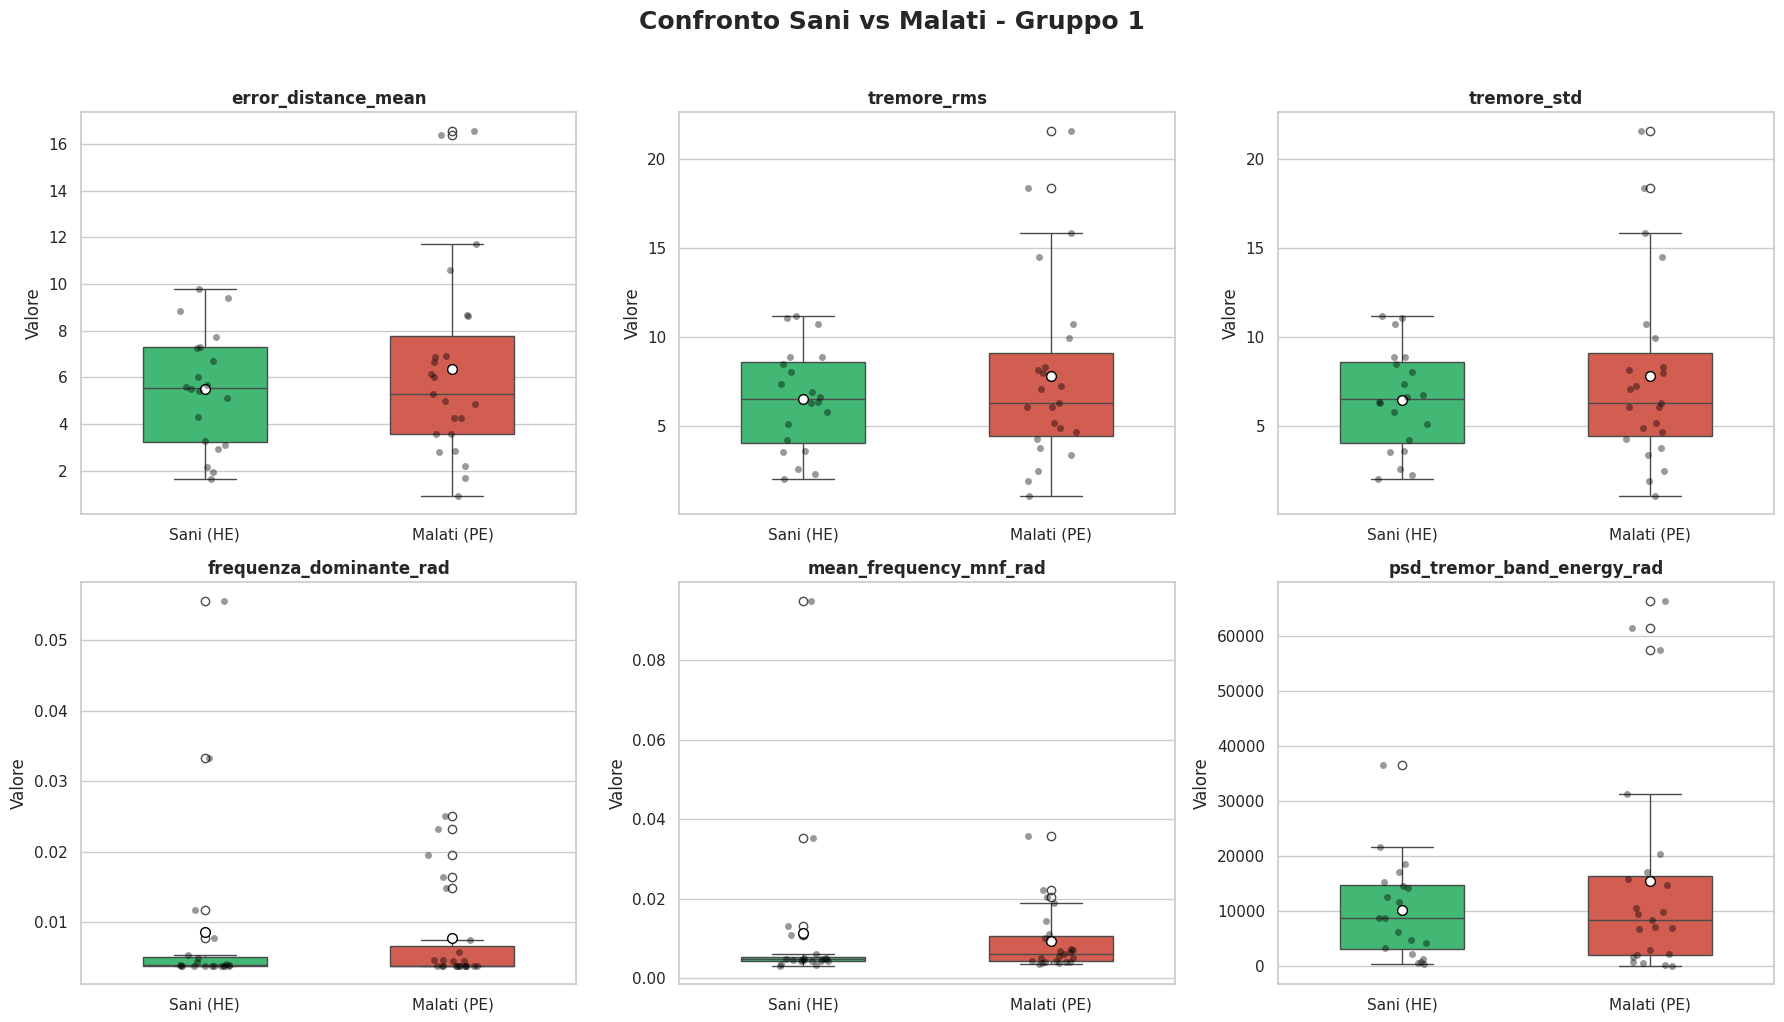

/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passin

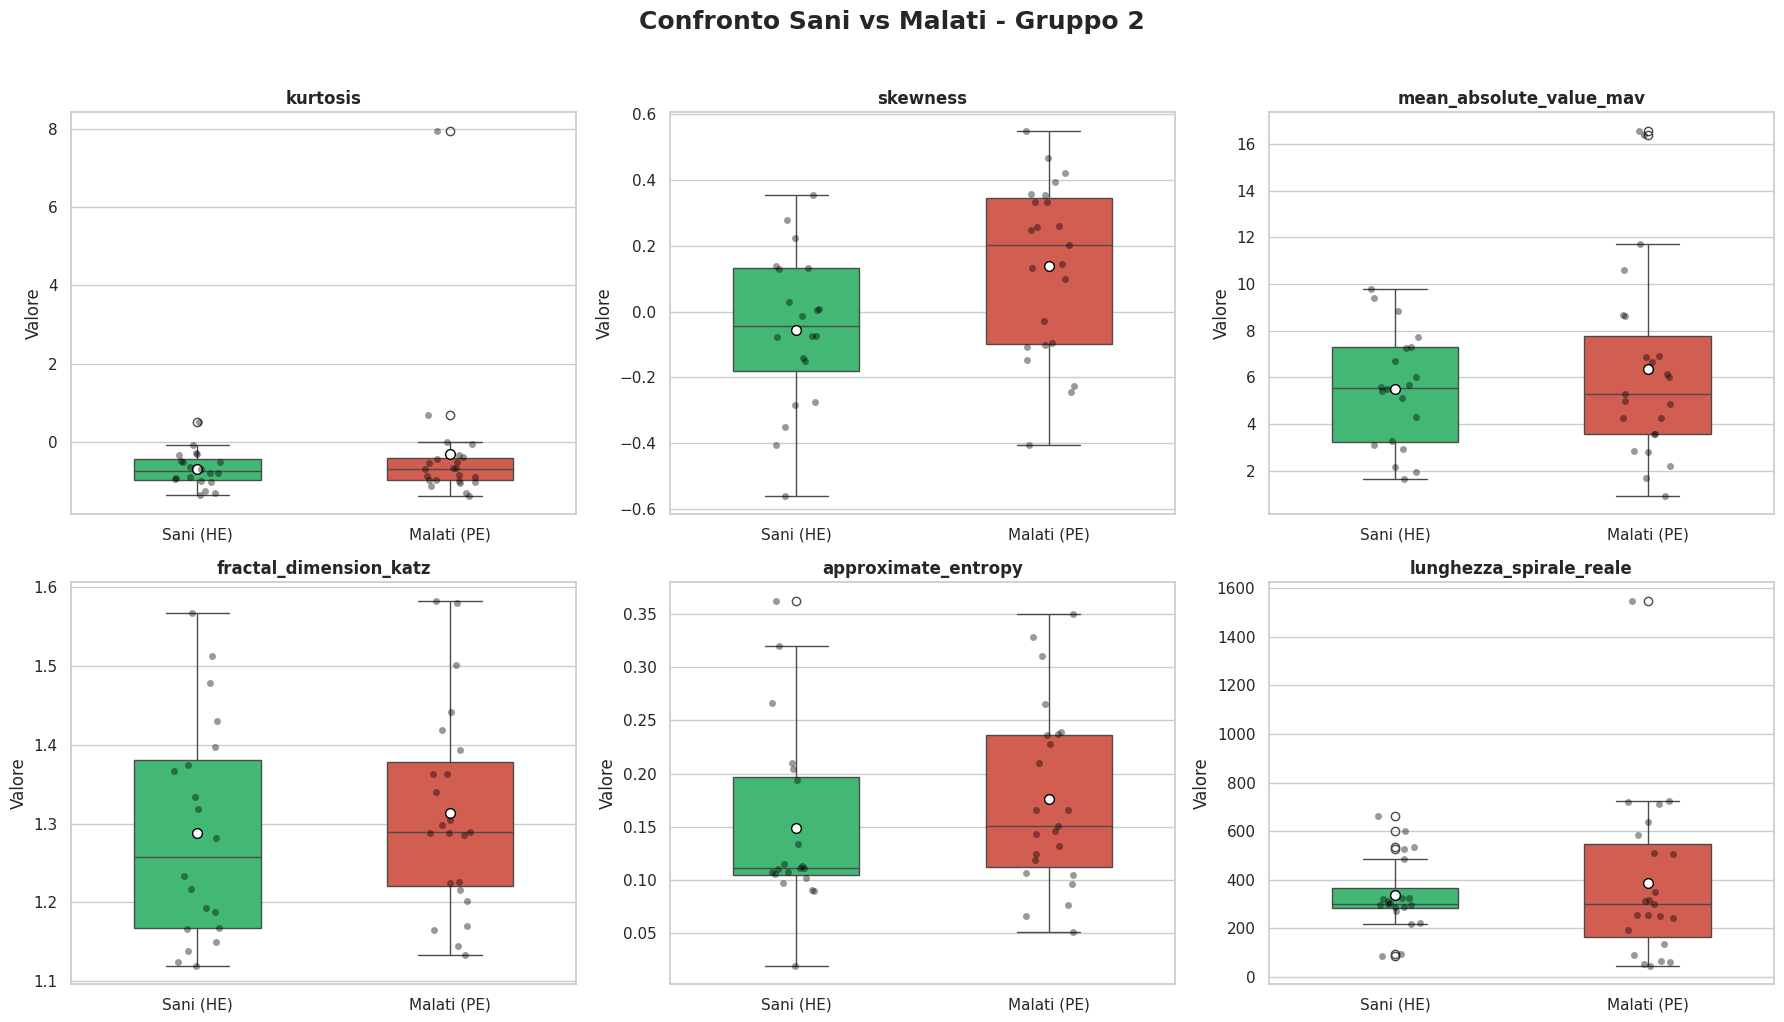

/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passin

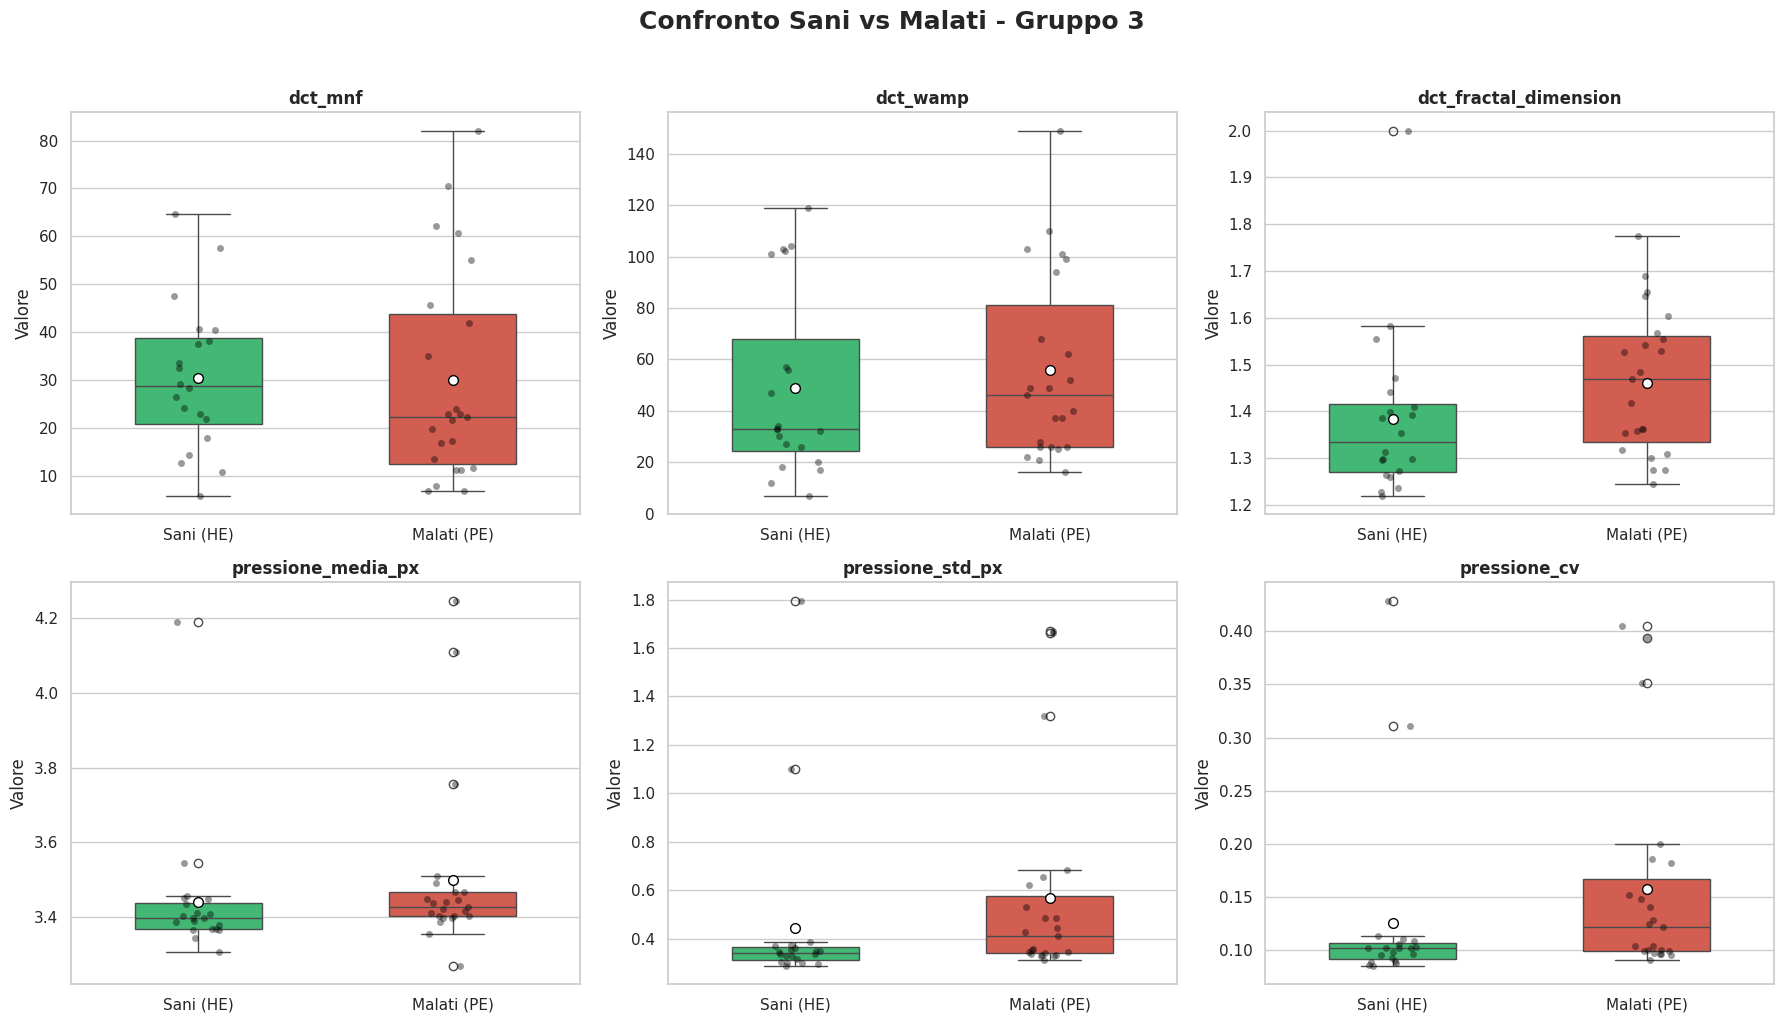

/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_708/2053844308.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


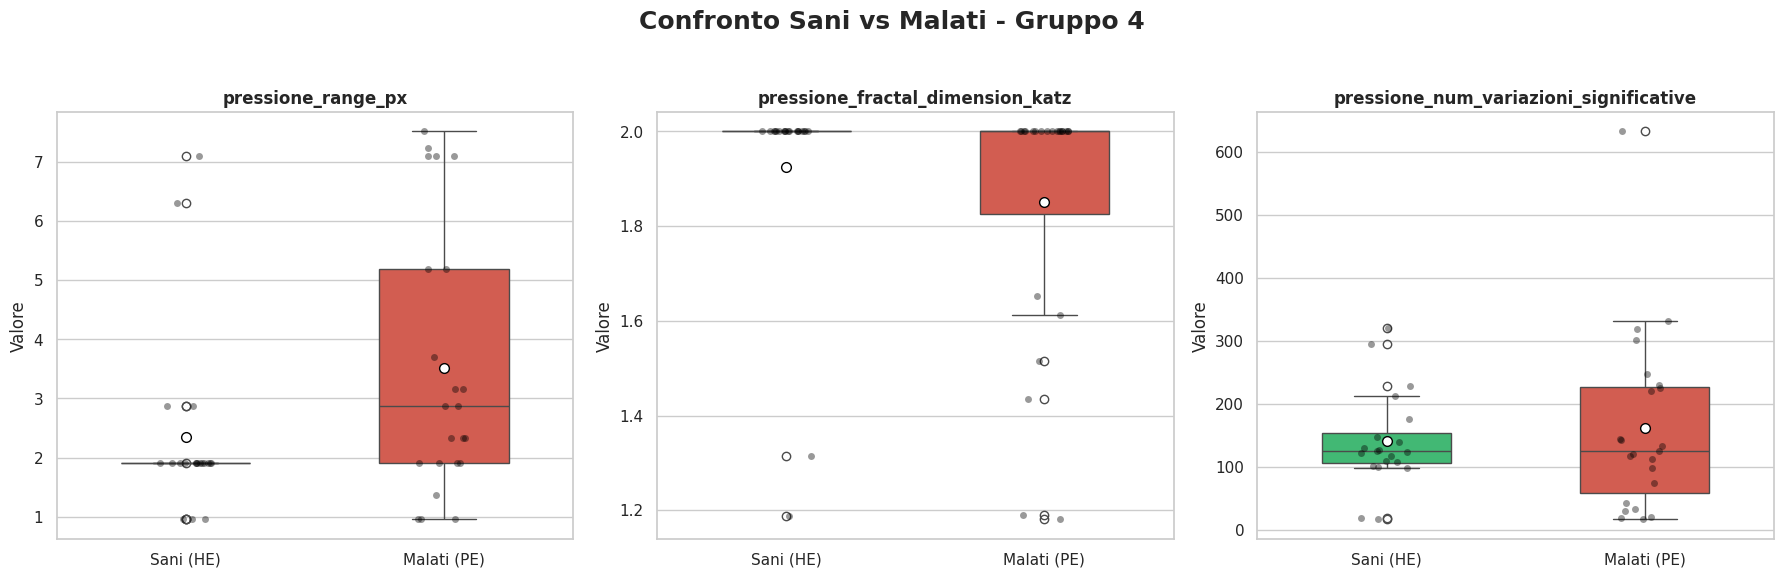

✅ Generazione di tutti i grafici comparativi completata!


In [ ]:
# @title
%matplotlib inline

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import re

print("📊 Generazione dei grafici comparativi completi (Sani vs Malati)...\n")

# 1. Recupero del DataFrame corretto
if 'df_dataset_completo' in locals():
    df_plot = df_dataset_completo.copy()
else:
    df_plot = df_features.copy()

# 2. Assegnazione dello stato del paziente
def estrai_stato_paziente(nome_file):
    match = re.search(r"V\d+(HE|PE)\d+", str(nome_file), re.IGNORECASE)
    if match:
        stato = match.group(1).upper()
        return "Sani (HE)" if stato == "HE" else "Malati (PE)"
    return "Non Classificato"

df_plot["Gruppo"] = df_plot["nome_file"].apply(estrai_stato_paziente)
df_plot = df_plot[df_plot["Gruppo"] != "Non Classificato"]

# 3. Lista completa di tutte le feature estratte (escludendo le colonne di testo/metadati)
colonne_da_escludere = {"nome_file", "paziente_id", "tipo_test", "visita", "percorso_file", "angolo_rotazione", "Gruppo"}
features_totali = [col for col in df_plot.columns if col not in colonne_da_escludere and pd.api.types.is_numeric_dtype(df_plot[col])]

print(f"Trovate {len(features_totali)} feature numeriche da graficare.\n")

# 4. Impostazioni grafiche
sns.set_theme(style="whitegrid", palette="muted")
palette_colori = {"Sani (HE)": "#2ecc71", "Malati (PE)": "#e74c3c"}

# Dividiamo le feature in blocchi da 6 per creare più griglie pulite e leggibili
chunk_size = 6
for i in range(0, len(features_totali), chunk_size):
    chunk = features_totali[i:i + chunk_size]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f"Confronto Sani vs Malati - Gruppo {i//chunk_size + 1}", fontsize=18, fontweight='bold', y=1.02)

    axes_flat = axes.flatten()
    for idx, feature in enumerate(chunk):
        ax = axes_flat[idx]
        sns.boxplot(
            data=df_plot,
            x="Gruppo",
            y=feature,
            ax=ax,
            palette=palette_colori,
            width=0.5,
            showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"7"}
        )
        sns.stripplot(
            data=df_plot,
            x="Gruppo",
            y=feature,
            ax=ax,
            color="black",
            alpha=0.4,
            jitter=True
        )
        ax.set_title(feature, fontsize=12, fontweight='bold')
        ax.set_xlabel("")
        ax.set_ylabel("Valore")

    # Nasconde eventuali assi vuoti se l'ultimo blocco ha meno di 6 feature
    for j in range(len(chunk), len(axes_flat)):
        fig.delaxes(axes_flat[j])

    plt.tight_layout()
    plt.show()

print("✅ Generazione di tutti i grafici comparativi completata!")

# T Test

In [ ]:
# 1. Carica il dataset
df = pd.read_csv("/content/drive/MyDrive/solo_features_spirali_complete.csv")

if 'Classe' not in df.columns:
    df['Classe'] = df['nome_file'].apply(lambda x: 'HE' if 'HE' in x.upper() else 'PE')

feature_cols = [col for col in df.columns if col not in ['nome_file', 'Classe']]
risultati_mwu = []

# Esegui il Test di Mann-Whitney per ogni feature
for feature in feature_cols:
    sani = df[df['Classe'] == 'HE'][feature].dropna()
    malati = df[df['Classe'] == 'PE'][feature].dropna()

    # Test non-parametrico: perfetto per dati con outlier e varianza diversa
    stat, p_val = mannwhitneyu(sani, malati, alternative='two-sided')

    risultati_mwu.append({
        "Feature": feature,
        "Mediana Sani (HE)": sani.median(),   # Usiamo la mediana, non la media!
        "Mediana Malati (PE)": malati.median(),
        "P-Value": p_val,
        "Significativa": "✅ Sì" if p_val < 0.05 else "❌ No"
    })

df_mwu = pd.DataFrame(risultati_mwu).sort_values(by="P-Value").reset_index(drop=True)
display(df_mwu)

,Feature,Mediana Sani (HE),Mediana Malati (PE),P-Value,Significativa
0,skewness,-0.043323,0.204319,0.021391,✅ Sì
1,pressione_std_px,0.341193,0.410665,0.031169,✅ Sì
2,pressione_cv,0.101949,0.122417,0.035186,✅ Sì
3,pressione_range_px,1.910000,2.865000,0.038767,✅ Sì
4,dct_fractal_dimension,1.334085,1.468804,0.039637,✅ Sì
5,pressione_media_px,3.396592,3.425560,0.055951,❌ No
6,approximate_entropy,0.111304,0.151102,0.192683,❌ No
7,pressione_fractal_dimension_katz,2.000000,2.000000,0.229548,❌ No
8,mean_frequency_mnf_rad,0.004770,0.006026,0.278568,❌ No
9,fractal_dimension_katz,1.257485,1.289459,0.472571,❌ No
